# Final Results Tables and Figures

This notebook is an artifact reader for the final paper-facing results. It reads saved CSV/parquet files from `data/results/`, applies lightweight ordering and formatting, writes clean final CSV artifacts, and saves publication-ready figures under `data/results/figures/`.

It does not train models, recompute predictions, or overwrite frozen baseline artifacts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "data" / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

FINAL_ROSTER = [
    "HAR per-stock",
    "HAR pooled",
    "LSTM",
    "GNN-Correlation",
    "GNN-Sector",
    "GNN-Granger",
    "GNN-Ensemble",
    "GNN-Correlation + Macro Tuned",
    "GNN-Correlation + Macro 21d Tuned",
    "GNN-Correlation + Macro 63d Tuned",
    "GNN-Correlation + Macro 126d Tuned",
    "GNN-Sector + Macro",
    "GNN-Granger + Macro",
    "GNN-Ensemble + Macro",
]

EXPLORATORY_MODELS = [
    "GNN-Correlation + Macro",
    "LSTM + Macro",
]

PORTFOLIO_ROSTER = FINAL_ROSTER + ["Equal-weight"]

FOCUSED_CALIBRATION_MODELS = [
    "HAR per-stock",
    "LSTM",
    "GNN-Correlation",
    "GNN-Correlation + Macro Tuned",
    "GNN-Correlation + Macro 21d Tuned",
    "GNN-Correlation + Macro 63d Tuned",
    "GNN-Correlation + Macro 126d Tuned",
    "GNN-Sector + Macro",
    "GNN-Granger + Macro",
]

FOCUSED_PORTFOLIO_MODELS = [
    "Equal-weight",
    "HAR per-stock",
    "LSTM",
    "GNN-Ensemble",
    "GNN-Correlation + Macro Tuned",
    "GNN-Correlation + Macro 21d Tuned",
    "GNN-Correlation + Macro 63d Tuned",
    "GNN-Correlation + Macro 126d Tuned",
    "GNN-Ensemble + Macro",
]

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update(
    {
        "figure.dpi": 140,
        "savefig.dpi": 300,
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def read_csv(name):
    path = RESULTS / name
    if not path.exists():
        raise FileNotFoundError(f"Missing required artifact: {path}")
    return pd.read_csv(path)


def ordered(df, roster, model_col="model"):
    out = df[df[model_col].isin(roster)].copy()
    order = {name: i for i, name in enumerate(roster)}
    out["_order"] = out[model_col].map(order)
    out = out.sort_values("_order").drop(columns="_order")
    return out


def save_final(df, name):
    path = RESULTS / name
    df.to_csv(path, index=False)
    return path


def rounded(df, decimals=4):
    out = df.copy()
    numeric_cols = out.select_dtypes(include=["number"]).columns
    out[numeric_cols] = out[numeric_cols].round(decimals)
    return out


def display_table(title, df, decimals=4):
    display(Markdown(f"### {title}"))
    display(rounded(df, decimals))


def model_colors(models):
    colors = []
    for model in models:
        if "Macro" in model:
            colors.append("#2f7d59")
        elif model == "Equal-weight":
            colors.append("#6b7280")
        elif model.startswith("HAR"):
            colors.append("#4c78a8")
        elif model == "LSTM":
            colors.append("#b279a2")
        else:
            colors.append("#f58518")
    return colors


def horizontal_bar(df, x_col, y_col, title, xlabel, path, value_fmt="{:.4f}"):
    plot_df = df[[y_col, x_col]].dropna().copy()
    plot_df = plot_df.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.2, 5.2))
    bars = ax.barh(
        plot_df[y_col],
        plot_df[x_col],
        color=model_colors(plot_df[y_col]),
        alpha=0.92,
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    for bar, value in zip(bars, plot_df[x_col]):
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            "  " + value_fmt.format(value),
            va="center",
            fontsize=8,
        )
    ax.margins(x=0.12)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    return path


print(f"Reading artifacts from: {RESULTS}")
print(f"Saving figures to: {FIGURES}")

Reading artifacts from: <project-root>\data\results
Saving figures to: <project-root>\data\results\figures


## 1. ML Metrics

The headline ML table is restricted to the final model roster. Exploratory variants such as untuned `GNN-Correlation + Macro` and `LSTM + Macro` are not included in this main table.

In [2]:
ml_metrics = read_csv("ml_metrics_table.csv")
final_ml = ordered(ml_metrics, FINAL_ROSTER)[["model", "mse", "mae", "r2", "da"]]
ml_path = save_final(final_ml, "final_ml_metrics_table.csv")
display_table("Final ML Metrics", final_ml)
print(f"Saved: {ml_path.relative_to(ROOT)}")

### Final ML Metrics

,model,mse,mae,r2,da
10,HAR per-stock,0.0329,0.1129,0.1307,0.7070
11,HAR pooled,0.0331,0.1133,0.1242,0.7030
9,LSTM,0.0324,0.1096,0.1422,0.7088
8,GNN-Correlation,0.0322,0.1076,0.1484,0.7122
13,GNN-Sector,0.0336,0.1208,0.1102,0.6822
14,GNN-Granger,0.0337,0.1190,0.1084,0.6879
6,GNN-Ensemble,0.0320,0.1127,0.1531,0.7004
1,GNN-Correlation + Macro Tuned,0.0309,0.1070,0.1828,0.7197
2,GNN-Correlation + Macro 21d Tuned,0.0311,0.1043,0.1771,0.7250
0,GNN-Correlation + Macro 63d Tuned,0.0298,0.1042,0.2104,0.7217


Saved: data\results\final_ml_metrics_table.csv


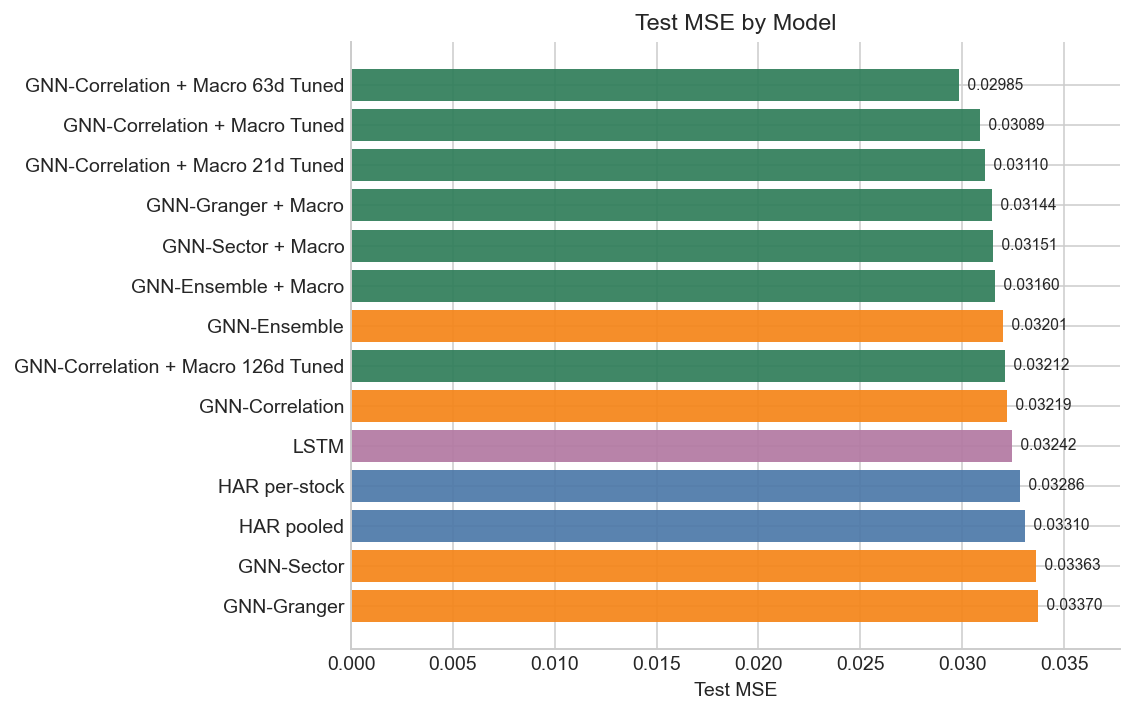

Saved: data\results\figures\final_test_mse_by_model.png


In [3]:
mse_fig = horizontal_bar(
    final_ml.sort_values("mse", ascending=True),
    x_col="mse",
    y_col="model",
    title="Test MSE by Model",
    xlabel="Test MSE",
    path=FIGURES / "final_test_mse_by_model.png",
    value_fmt="{:.5f}",
)
print(f"Saved: {mse_fig.relative_to(ROOT)}")

## 2. Rank IC / ICIR

Rank metrics evaluate whether models correctly order stocks by next-week realized volatility. The table includes hit-rate and pairwise-accuracy columns when present in the saved artifact.

In [4]:
rank_ic = read_csv("rank_ic_table.csv")
rank_cols = ["model", "mean_ic", "ic_ir"]
for optional in ["pct_positive", "top_quartile_hit_rate", "pairwise_accuracy"]:
    if optional in rank_ic.columns:
        rank_cols.append(optional)
final_rank = ordered(rank_ic, FINAL_ROSTER)[rank_cols]
rank_path = save_final(final_rank, "final_rank_ic_table.csv")
display_table("Final Rank IC Metrics", final_rank)
print(f"Saved: {rank_path.relative_to(ROOT)}")

### Final Rank IC Metrics

,model,mean_ic,ic_ir,pct_positive,top_quartile_hit_rate,pairwise_accuracy
12,HAR per-stock,0.4049,3.4728,1.0,0.4859,0.6407
13,HAR pooled,0.3923,3.4370,1.0,0.4784,0.6355
4,LSTM,0.4288,4.3626,1.0,0.4990,0.6484
8,GNN-Correlation,0.4165,3.4399,1.0,0.4919,0.6448
14,GNN-Sector,0.3826,3.3994,1.0,0.4787,0.6330
15,GNN-Granger,0.3749,3.6630,1.0,0.4726,0.6293
9,GNN-Ensemble,0.4162,3.5769,1.0,0.4936,0.6451
5,GNN-Correlation + Macro Tuned,0.4286,3.6803,1.0,0.5023,0.6491
11,GNN-Correlation + Macro 21d Tuned,0.4120,3.9145,1.0,0.4958,0.6429
7,GNN-Correlation + Macro 63d Tuned,0.4260,3.6569,1.0,0.5021,0.6481


Saved: data\results\final_rank_ic_table.csv


Rank IC and ICIR measure a different objective than MSE. Stronger ranking does not automatically imply better calibrated volatility levels or better portfolio behavior.

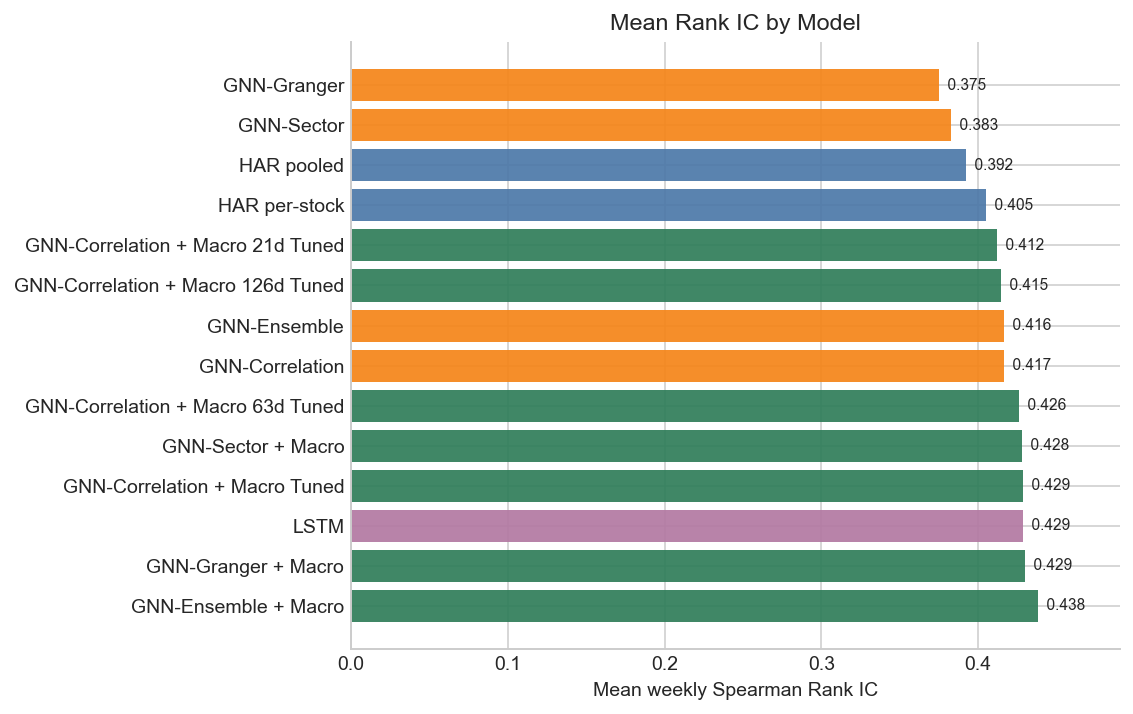

Saved: data\results\figures\final_rank_ic_by_model.png


In [5]:
rank_fig = horizontal_bar(
    final_rank.sort_values("mean_ic", ascending=True),
    x_col="mean_ic",
    y_col="model",
    title="Mean Rank IC by Model",
    xlabel="Mean weekly Spearman Rank IC",
    path=FIGURES / "final_rank_ic_by_model.png",
    value_fmt="{:.3f}",
)
print(f"Saved: {rank_fig.relative_to(ROOT)}")

## 3. Calibration

Calibration summaries and decile plots show whether predicted volatility levels line up with realized volatility levels. This matters for inverse-volatility and minimum-variance portfolio construction.

In [6]:
calibration = read_csv("calibration_summary.csv")
calibration_bins = read_csv("calibration_bins.csv")
cal_cols = [
    "model",
    "calibration_slope",
    "calibration_intercept",
    "pearson_corr",
    "prediction_mean",
    "prediction_std",
    "prediction_min",
    "prediction_max",
    "avg_weekly_prediction_spread_p90_p10",
]
final_calibration = ordered(calibration, FINAL_ROSTER)[cal_cols]
cal_path = save_final(final_calibration, "final_calibration_summary.csv")
display_table("Final Calibration Summary", final_calibration)
print(f"Saved: {cal_path.relative_to(ROOT)}")

### Final Calibration Summary

,model,calibration_slope,calibration_intercept,pearson_corr,prediction_mean,prediction_std,prediction_min,prediction_max,avg_weekly_prediction_spread_p90_p10
12,HAR per-stock,0.7452,0.0637,0.3847,0.2538,0.1004,0.0643,3.1389,0.2017
13,HAR pooled,0.7429,0.0642,0.3756,0.2539,0.0983,0.1001,2.2918,0.1799
14,LSTM,0.9297,0.0231,0.3793,0.2471,0.0793,0.0858,1.9006,0.1673
0,GNN-Correlation,1.1827,-0.0251,0.4007,0.2350,0.0659,0.0929,0.8642,0.1325
10,GNN-Sector,0.9324,-0.0052,0.3550,0.2767,0.0740,0.0341,0.7675,0.1642
8,GNN-Granger,0.8731,0.0169,0.3448,0.2702,0.0768,0.1358,0.8644,0.1564
6,GNN-Ensemble,1.1581,-0.0475,0.3964,0.2594,0.0665,0.1218,0.7485,0.1410
5,GNN-Correlation + Macro Tuned,0.7678,0.0628,0.4495,0.2475,0.1138,0.0938,1.7943,0.1644
3,GNN-Correlation + Macro 21d Tuned,0.9069,0.0459,0.4419,0.2281,0.0947,0.0942,1.7602,0.1286
4,GNN-Correlation + Macro 63d Tuned,1.0298,0.0103,0.4675,0.2355,0.0883,0.0617,1.5335,0.1431


Saved: data\results\final_calibration_summary.csv


A well-ranked model can still be poorly calibrated if its slope, intercept, or prediction spread are distorted. The final narrative should keep ranking and level calibration separate.

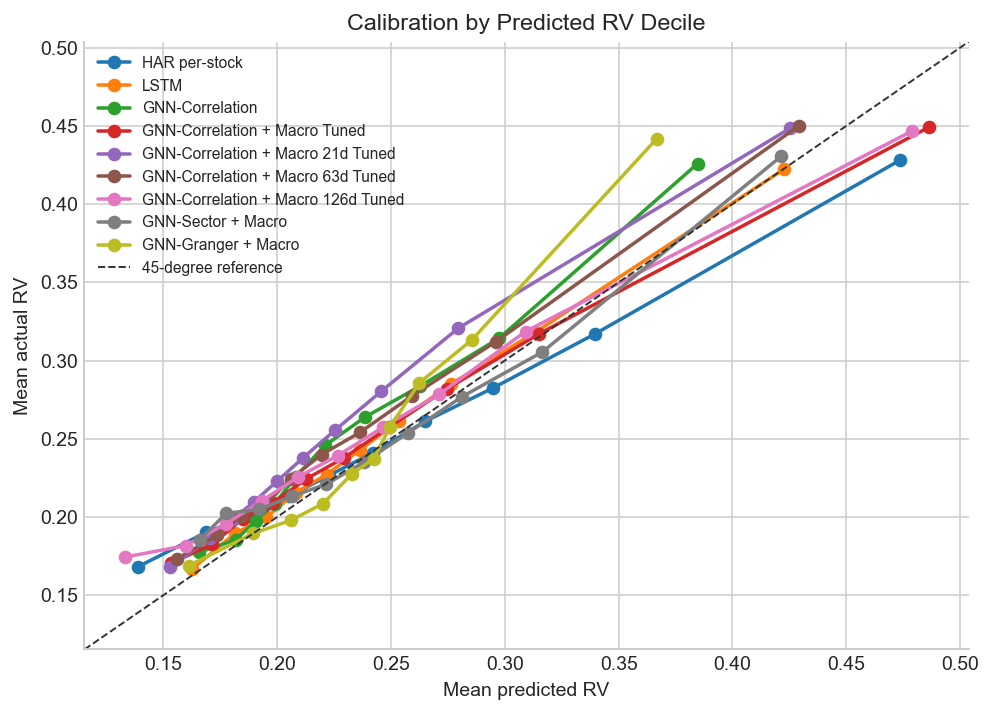

Saved: data\results\figures\final_calibration_by_predicted_rv.png


In [7]:
plot_bins = calibration_bins[
    calibration_bins["model"].isin(FOCUSED_CALIBRATION_MODELS)
].copy()
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for model in FOCUSED_CALIBRATION_MODELS:
    model_bins = plot_bins[plot_bins["model"] == model].sort_values("decile")
    if model_bins.empty:
        continue
    ax.plot(
        model_bins["predicted_rv_mean"],
        model_bins["actual_rv_mean"],
        marker="o",
        linewidth=1.8,
        label=model,
    )
lims = [
    min(plot_bins["predicted_rv_mean"].min(), plot_bins["actual_rv_mean"].min()),
    max(plot_bins["predicted_rv_mean"].max(), plot_bins["actual_rv_mean"].max()),
]
pad = (lims[1] - lims[0]) * 0.05
lims = [lims[0] - pad, lims[1] + pad]
ax.plot(
    lims,
    lims,
    color="#333333",
    linestyle="--",
    linewidth=1,
    label="45-degree reference",
)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_title("Calibration by Predicted RV Decile")
ax.set_xlabel("Mean predicted RV")
ax.set_ylabel("Mean actual RV")
ax.legend(frameon=False, fontsize=8, loc="best")
fig.tight_layout()
cal_fig = FIGURES / "final_calibration_by_predicted_rv.png"
fig.savefig(cal_fig, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Saved: {cal_fig.relative_to(ROOT)}")

## 4. Portfolio Metrics

These tables summarize the saved portfolio evaluations by strategy. Equal-weight is retained where it exists as a strategy benchmark.

In [8]:
portfolio_specs = [
    (
        "Inverse-Volatility",
        "portfolio_metrics_table.csv",
        "final_portfolio_inverse_vol_metrics.csv",
        PORTFOLIO_ROSTER,
    ),
    (
        "Long-Short",
        "portfolio_ls_metrics_table.csv",
        "final_portfolio_long_short_metrics.csv",
        FINAL_ROSTER,
    ),
    (
        "Volatility-Targeted",
        "portfolio_vt_metrics_table.csv",
        "final_portfolio_vol_target_metrics.csv",
        FINAL_ROSTER,
    ),
    (
        "Minimum-Variance",
        "portfolio_mv_metrics_table.csv",
        "final_portfolio_minvar_metrics.csv",
        FINAL_ROSTER,
    ),
]
final_portfolio_tables = {}
for title, source, output, roster in portfolio_specs:
    df = read_csv(source)
    cols = [
        c
        for c in [
            "model",
            "ann_return",
            "ann_vol",
            "sharpe",
            "max_drawdown",
            "avg_turnover",
            "max_single_stock_weight",
            "max_long_weight",
            "avg_equity_weight",
        ]
        if c in df.columns
    ]
    final_df = ordered(df, roster)[cols]
    final_portfolio_tables[title] = final_df
    out_path = save_final(final_df, output)
    display_table(f"Final Portfolio Metrics: {title}", final_df)
    print(f"Saved: {out_path.relative_to(ROOT)}")

### Final Portfolio Metrics: Inverse-Volatility

,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_single_stock_weight
0,HAR per-stock,0.0999,0.1261,0.3956,-0.1548,0.1634,0.0077
1,HAR pooled,0.1018,0.1276,0.4060,-0.1586,0.1521,0.0049
2,LSTM,0.1021,0.1267,0.4111,-0.1580,0.0758,0.0057
4,GNN-Correlation,0.0994,0.1277,0.3869,-0.1592,0.0787,0.0050
10,GNN-Sector,0.1027,0.1287,0.4097,-0.1573,0.0719,0.0161
12,GNN-Granger,0.1046,0.1290,0.4234,-0.1604,0.0818,0.0039
14,GNN-Ensemble,0.1035,0.1283,0.4168,-0.1586,0.0581,0.0040
6,GNN-Correlation + Macro Tuned,0.1031,0.1249,0.4251,-0.1510,0.0902,0.0081
7,GNN-Correlation + Macro 21d Tuned,0.1077,0.1279,0.4511,-0.1562,0.0913,0.0050
8,GNN-Correlation + Macro 63d Tuned,0.1041,0.1260,0.4292,-0.1538,0.0781,0.0068


Saved: data\results\final_portfolio_inverse_vol_metrics.csv


### Final Portfolio Metrics: Long-Short

,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_long_weight
0,HAR per-stock,-0.1686,0.1621,-1.3492,-0.3587,1.3298,0.0086
1,HAR pooled,-0.1919,0.1528,-1.5828,-0.3604,1.4774,0.0086
2,LSTM,-0.1565,0.1650,-1.2518,-0.3550,0.7648,0.0086
4,GNN-Correlation,-0.2644,0.1768,-1.7786,-0.4248,0.9674,0.0086
10,GNN-Sector,-0.1705,0.1750,-1.2594,-0.3684,0.7861,0.0086
12,GNN-Granger,-0.1550,0.1568,-1.3075,-0.3443,0.9829,0.0086
14,GNN-Ensemble,-0.1849,0.1819,-1.2913,-0.3927,0.7201,0.0086
6,GNN-Correlation + Macro Tuned,-0.1794,0.1909,-1.2016,-0.3703,0.8420,0.0086
7,GNN-Correlation + Macro 21d Tuned,-0.1611,0.1706,-1.2373,-0.3530,1.0896,0.0086
8,GNN-Correlation + Macro 63d Tuned,-0.1743,0.1861,-1.2057,-0.3725,0.9029,0.0086


...

,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_single_stock_weight,avg_equity_weight
0,HAR per-stock,0.0384,0.0530,-0.2193,-0.0670,0.0763,0.0032,0.4333
1,HAR pooled,0.0388,0.0538,-0.2077,-0.0686,0.0734,0.0021,0.4364
2,LSTM,0.0437,0.0554,-0.1140,-0.0711,0.0335,0.0024,0.4373
4,GNN-Correlation,0.0385,0.0594,-0.1928,-0.0756,0.0523,0.0024,0.4646
10,GNN-Sector,0.0392,0.0489,-0.2196,-0.0611,0.0281,0.0062,0.3813
12,GNN-Granger,0.0397,0.0513,-0.1998,-0.0661,0.0369,0.0016,0.3996
14,GNN-Ensemble,0.0396,0.0528,-0.1964,-0.0673,0.0295,0.0018,0.4130
6,GNN-Correlation + Macro Tuned,0.0300,0.0556,-0.3586,-0.0682,0.0661,0.0023,0.4494
7,GNN-Correlation + Macro 21d Tuned,0.0449,0.0600,-0.0855,-0.0733,0.0604,0.0022,0.4859
8,GNN-Correlation + Macro 63d Tuned,0.0404,0.0561,-0.1717,-0.0667,0.0531,0.0035,0.4675


Saved: data\results\final_portfolio_vol_target_metrics.csv


### Final Portfolio Metrics: Minimum-Variance

,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_single_stock_weight
0,HAR per-stock,0.1126,0.0986,0.6346,-0.1273,1.0121,0.05
1,HAR pooled,0.1245,0.1021,0.7289,-0.1189,0.9135,0.05
2,LSTM,0.1118,0.1096,0.5637,-0.1141,0.5914,0.05
4,GNN-Correlation,0.1183,0.1175,0.5814,-0.1276,0.6060,0.05
10,GNN-Sector,0.1043,0.1104,0.4918,-0.0891,0.5329,0.05
12,GNN-Granger,0.0963,0.1123,0.4119,-0.1296,0.6760,0.05
14,GNN-Ensemble,0.1059,0.1122,0.4977,-0.1084,0.4915,0.05
6,GNN-Correlation + Macro Tuned,0.1175,0.1005,0.6711,-0.0856,0.7700,0.05
7,GNN-Correlation + Macro 21d Tuned,0.1372,0.1052,0.8284,-0.1031,0.7204,0.05
8,GNN-Correlation + Macro 63d Tuned,0.1334,0.1049,0.7945,-0.0922,0.6704,0.05


Saved: data\results\final_portfolio_minvar_metrics.csv


Portfolio outcomes depend on construction choices as well as forecast quality. The final paper should avoid treating a point-forecast win as equivalent to an investable performance win. Turnover is reported as realized weekly one-way rebalancing intensity, computed from the saved portfolio weights implicit in each backtest return series; at 10 bps, weekly transaction cost is turnover x 0.001.

In [9]:
portfolio_return_specs = [
    ("Inverse-Volatility", "portfolio_returns.parquet", PORTFOLIO_ROSTER),
    ("Long-Short", "portfolio_ls_returns.parquet", FINAL_ROSTER),
    ("Volatility-Targeted", "portfolio_vt_returns.parquet", FINAL_ROSTER),
    ("Minimum-Variance", "portfolio_mv_returns.parquet", FINAL_ROSTER),
]


def portfolio_model_group(model):
    if model == "Equal-weight":
        return "Equal-weight"
    if model.startswith("HAR"):
        return "HAR"
    if model.startswith("LSTM"):
        return "LSTM"
    if "Macro" in model:
        return "Macro GNN"
    if model.startswith("GNN"):
        return "Baseline GNN"
    return "Other"

turnover_rows = []
for strategy, source, roster in portfolio_return_specs:
    df = pd.read_parquet(RESULTS / source)
    df = df[df["model"].isin(roster)].copy()
    df["strategy"] = strategy
    df["model_group"] = df["model"].map(portfolio_model_group)
    turnover_rows.append(df[["strategy", "model_group", "model", "turnover"]])

turnover = pd.concat(turnover_rows, ignore_index=True)
model_turnover = (
    turnover.groupby(["strategy", "model_group", "model"], as_index=False)
    .agg(avg_weekly_turnover=("turnover", "mean"))
)
turnover_summary = (
    model_turnover.groupby(["strategy", "model_group"], as_index=False)
    .agg(
        models=("model", "nunique"),
        avg_weekly_turnover=("avg_weekly_turnover", "mean"),
        min_model_turnover=("avg_weekly_turnover", "min"),
        max_model_turnover=("avg_weekly_turnover", "max"),
    )
)
turnover_summary["implied_weekly_cost_10bps"] = turnover_summary["avg_weekly_turnover"] * 0.001
strategy_order = {name: i for i, (name, _, _) in enumerate(portfolio_return_specs)}
group_order = {
    "Equal-weight": 0,
    "HAR": 1,
    "LSTM": 2,
    "Baseline GNN": 3,
    "Macro GNN": 4,
}
turnover_summary["_strategy_order"] = turnover_summary["strategy"].map(strategy_order)
turnover_summary["_group_order"] = turnover_summary["model_group"].map(group_order).fillna(99)
turnover_summary = turnover_summary.sort_values(["_strategy_order", "_group_order"]).drop(
    columns=["_strategy_order", "_group_order"]
)
out_path = save_final(turnover_summary, "final_portfolio_turnover_by_strategy_group.csv")
display_table("Realized Weekly Turnover by Portfolio Strategy and Model Group", turnover_summary, decimals=4)
print(f"Saved: {out_path.relative_to(ROOT)}")

### Realized Weekly Turnover by Portfolio Strategy and Model Group

,strategy,model_group,models,avg_weekly_turnover,min_model_turnover,max_model_turnover,implied_weekly_cost_10bps
1,Inverse-Volatility,Equal-weight,1,0.0000,0.0000,0.0000,0.0000
2,Inverse-Volatility,HAR,2,0.1578,0.1521,0.1634,0.0002
3,Inverse-Volatility,LSTM,1,0.0758,0.0758,0.0758,0.0001
0,Inverse-Volatility,Baseline GNN,4,0.0726,0.0581,0.0818,0.0001
4,Inverse-Volatility,Macro GNN,7,0.0733,0.0372,0.1135,0.0001
6,Long-Short,HAR,2,1.4036,1.3298,1.4774,0.0014
7,Long-Short,LSTM,1,0.7648,0.7648,0.7648,0.0008
5,Long-Short,Baseline GNN,4,0.8641,0.7201,0.9829,0.0009
8,Long-Short,Macro GNN,7,0.8063,0.5517,1.0896,0.0008
14,Volatility-Targeted,HAR,2,0.0748,0.0734,0.0763,0.0001


Saved: data\results\final_portfolio_turnover_by_strategy_group.csv


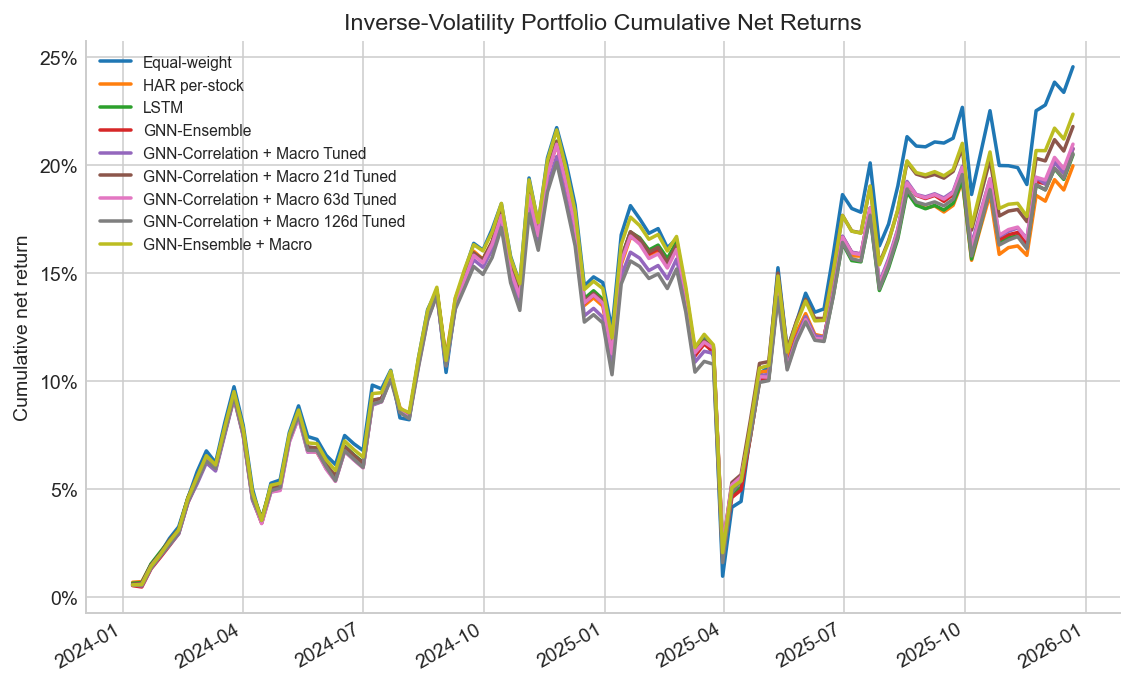

Saved: data\results\figures\final_portfolio_cumulative_returns.png


In [10]:
returns = pd.read_parquet(RESULTS / "portfolio_returns.parquet")
returns["week"] = pd.to_datetime(returns["week"])
plot_returns = returns[returns["model"].isin(FOCUSED_PORTFOLIO_MODELS)].copy()
plot_returns = plot_returns.sort_values(["model", "week"])
plot_returns["cum_net_return"] = plot_returns.groupby("model")[
    "net_return"
].transform(lambda s: (1 + s).cumprod() - 1)

fig, ax = plt.subplots(figsize=(8.2, 5.0))
for model in FOCUSED_PORTFOLIO_MODELS:
    model_returns = plot_returns[plot_returns["model"] == model]
    if model_returns.empty:
        continue
    ax.plot(
        model_returns["week"],
        model_returns["cum_net_return"],
        linewidth=1.8,
        label=model,
    )
ax.set_title("Inverse-Volatility Portfolio Cumulative Net Returns")
ax.set_xlabel("")
ax.set_ylabel("Cumulative net return")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(frameon=False, fontsize=8, loc="best")
fig.autofmt_xdate()
fig.tight_layout()
portfolio_fig = FIGURES / "final_portfolio_cumulative_returns.png"
fig.savefig(portfolio_fig, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Saved: {portfolio_fig.relative_to(ROOT)}")

The statistical-test section should govern final performance claims. A macro point-estimate improvement should not be described as statistically significant unless the adjusted tests support that statement.

## 7. Macro-vs-Baseline Deltas

This section is explicitly a macro comparison table. It includes the tuned macro correlation GNN and also keeps exploratory macro variants clearly separated from the main headline model tables.

In [13]:
macro_ml = read_csv("macro_ml_metric_deltas.csv")
macro_port = read_csv("macro_portfolio_metric_deltas.csv")

macro_ml_final = macro_ml[
    macro_ml["macro_model"].isin(FINAL_ROSTER + EXPLORATORY_MODELS)
].copy()
macro_ml_final["strategy"] = "ml_metrics"
macro_ml_final["delta_sharpe"] = np.nan
macro_ml_final["delta_ann_return"] = np.nan
macro_ml_final["delta_source"] = "ML"
macro_ml_view = macro_ml_final[
    [
        "delta_source",
        "strategy",
        "baseline_model",
        "macro_model",
        "delta_mse",
        "delta_mae",
        "delta_r2",
        "delta_da",
        "delta_ann_return",
        "delta_sharpe",
    ]
]

macro_port_final = macro_port[
    macro_port["macro_model"].isin(FINAL_ROSTER + EXPLORATORY_MODELS)
].copy()
macro_port_final["delta_mse"] = np.nan
macro_port_final["delta_mae"] = np.nan
macro_port_final["delta_r2"] = np.nan
macro_port_final["delta_da"] = np.nan
macro_port_final["delta_source"] = "Portfolio"
macro_port_view = macro_port_final[
    [
        "delta_source",
        "strategy",
        "baseline_model",
        "macro_model",
        "delta_mse",
        "delta_mae",
        "delta_r2",
        "delta_da",
        "delta_ann_return",
        "delta_sharpe",
    ]
]

final_macro_deltas = pd.concat([macro_ml_view, macro_port_view], ignore_index=True)
final_macro_deltas = final_macro_deltas.sort_values(
    ["delta_source", "strategy", "baseline_model", "macro_model"]
)
macro_delta_path = save_final(
    final_macro_deltas, "final_macro_vs_baseline_deltas.csv"
)
display_table("Final Macro-vs-Baseline Deltas", final_macro_deltas, decimals=5)
print(f"Saved: {macro_delta_path.relative_to(ROOT)}")

### Final Macro-vs-Baseline Deltas

,delta_source,strategy,baseline_model,macro_model,delta_mse,delta_mae,delta_r2,delta_da,delta_ann_return,delta_sharpe
1,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro,0.00119,-0.00030,-0.03154,0.00420,NaN,NaN
5,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro 126d Tuned,-0.00007,0.00033,0.00175,0.00631,NaN,NaN
3,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro 21d Tuned,-0.00109,-0.00336,0.02877,0.01274,NaN,NaN
4,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro 63d Tuned,-0.00234,-0.00346,0.06203,0.00948,NaN,NaN
2,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro Tuned,-0.00130,-0.00065,0.03445,0.00750,NaN,NaN
8,ML,ml_metrics,GNN-Ensemble,GNN-Ensemble + Macro,-0.00041,-0.00542,0.01094,0.01439,NaN,NaN
7,ML,ml_metrics,GNN-Granger,GNN-Granger + Macro,-0.00226,-0.01134,0.05987,0.02568,NaN,NaN
6,ML,ml_metrics,GNN-Sector,GNN-Sector + Macro,-0.00212,-0.01020,0.05618,0.02203,NaN,NaN
0,ML,ml_metrics,LSTM,LSTM + Macro,0.00242,0.01516,-0.06404,-0.03516,NaN,NaN
10,Portfolio,inverse_vol,GNN-Correlation,GNN-Correlation + Macro,NaN,NaN,NaN,NaN,0.01024,0.07217


Saved: data\results\final_macro_vs_baseline_deltas.csv


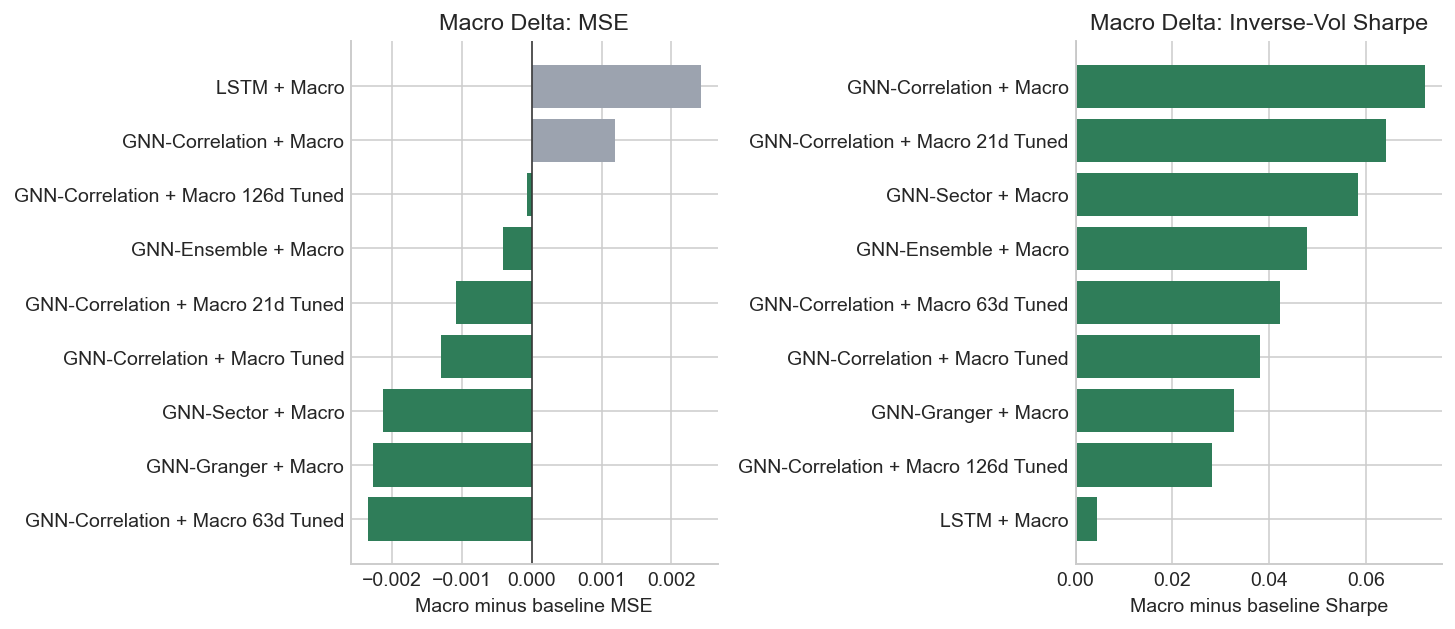

Saved: data\results\figures\final_macro_vs_baseline_deltas.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
ml_plot = macro_ml_final.sort_values("delta_mse")
axes[0].barh(
    ml_plot["macro_model"],
    ml_plot["delta_mse"],
    color=["#2f7d59" if v < 0 else "#9ca3af" for v in ml_plot["delta_mse"]],
)
axes[0].axvline(0, color="#333333", linewidth=0.8)
axes[0].set_title("Macro Delta: MSE")
axes[0].set_xlabel("Macro minus baseline MSE")
axes[0].set_ylabel("")

port_plot = macro_port_final[macro_port_final["strategy"] == "inverse_vol"].sort_values(
    "delta_sharpe"
)
axes[1].barh(
    port_plot["macro_model"],
    port_plot["delta_sharpe"],
    color=[
        "#2f7d59" if v > 0 else "#9ca3af" for v in port_plot["delta_sharpe"]
    ],
)
axes[1].axvline(0, color="#333333", linewidth=0.8)
axes[1].set_title("Macro Delta: Inverse-Vol Sharpe")
axes[1].set_xlabel("Macro minus baseline Sharpe")
axes[1].set_ylabel("")
fig.tight_layout()
macro_delta_fig = FIGURES / "final_macro_vs_baseline_deltas.png"
fig.savefig(macro_delta_fig, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Saved: {macro_delta_fig.relative_to(ROOT)}")

The tuned macro correlation GNN has the best saved point-estimate MSE, while macro Sharpe differences vary by strategy and baseline. Final claims should follow the matched DM and bootstrap summaries rather than the delta table alone.

## 9. Appendix: Exploratory Macro Variants

The following rows are intentionally excluded from headline tables because they are exploratory or not part of the final model roster. They are displayed here for auditability only.

In [17]:
appendix_rows = []
for source_name, df in [
    ("ML metrics", ml_metrics),
    ("Rank IC", rank_ic),
    ("Calibration", calibration),
]:
    subset = df[df["model"].isin(EXPLORATORY_MODELS)].copy()
    if subset.empty:
        continue
    subset.insert(0, "source", source_name)
    appendix_rows.append(subset)

if appendix_rows:
    display(Markdown("### Exploratory Model Rows"))
    for subset in appendix_rows:
        display(rounded(subset, 5))
else:
    display(Markdown("No exploratory model rows found in the saved artifacts."))

### Exploratory Model Rows

,source,model,mse,mae,r2,da
12,ML metrics,GNN-Correlation + Macro,0.03338,0.10734,0.11681,0.71642
15,ML metrics,LSTM + Macro,0.03484,0.12475,0.07814,0.67362


,source,model,mean_ic,ic_std,ic_tstat,ic_pvalue,ic_ir,n_weeks,pct_positive,top_quartile_hit_rate,pairwise_accuracy
0,Rank IC,LSTM + Macro,0.44701,0.10601,42.79455,0.0,4.21667,103,1.0,0.50737,0.65502
2,Rank IC,GNN-Correlation + Macro,0.43163,0.11167,39.22591,0.0,3.86504,103,1.0,0.49381,0.64230


,source,model,n_weeks,n_observations,prediction_mean,prediction_std,prediction_min,prediction_max,avg_weekly_prediction_spread_p90_p10,calibration_slope,calibration_intercept,pearson_corr,spearman_rank_ic
1,Calibration,GNN-Correlation + Macro,103,47895,0.22457,0.04652,0.17753,0.53868,0.08174,1.70470,-0.12998,0.40791,0.43163
15,Calibration,LSTM + Macro,103,47895,0.29620,0.11502,0.14215,1.70546,0.16509,0.68269,0.05062,0.40389,0.44701


## Output Manifest

The notebook wrote paper-facing CSVs under `data/results/` and PNG figures under `data/results/figures/`.